In [19]:
# ================================
# 1) Imports & working directory
# ================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# If you're on Windows, use a raw string or double backslashes:
# r = r'C:\DGA-GRU'
# os.chdir(r)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, GRU, Bidirectional, Dense, Dropout,
    SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

# For reproducibility (helps avoid extreme early overfitting)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)




In [20]:
# ================================
# 2) Load & tidy your dataset
# ================================
# Your original snippet:
# dga = pd.read_csv('dga-dataset.txt', sep=',', header=None)
# dga.columns = ['label','origin','domain']
# dga = dga.apply(lambda x: x.astype(str).str.lower())
# dga['domain_list'] = dga['domain'].apply(lambda x: x.split('.'))

# I’ll keep that logic but make it a bit safer:
dga = pd.read_csv('dga-dataset.txt', sep=',', header=None, names=['label','origin','domain'])
dga = dga.astype(str)
for col in dga.columns:
    dga[col] = dga[col].str.strip().str.lower()

# Basic cleaning: drop obviously bad rows
dga = dga[dga['domain'].str.len() > 0].dropna(subset=['domain'])

# Optional: keep only the SLD (before the first dot) to reduce leakage from TLDs.
# Comment this out if you want the full domain.
def get_sld(domain: str):
    parts = domain.split('.')
    return parts[0] if len(parts) > 0 else domain

dga['domain_sld'] = dga['domain'].apply(get_sld)



In [21]:
# ================================
# 3) Encode labels robustly
# ================================
def to_binary_label(x: str):
    x = x.strip().lower()
    # Numeric 0/1 as strings
    if x in {'0','1'}:
        return int(x)
    # Common text labels
    if x in {'benign','good','legit','normal','clean','ben'}:
        return 0
    if x in {'malicious','dga','bad','malware','mal','botnet'}:
        return 1
    # Try last resort: raise error to surface unexpected labels
    raise ValueError(f"Unrecognized label: {x}")

y = dga['label'].apply(to_binary_label).astype(int).values



In [22]:
# ================================
# 4) Character-level tokenization
# ================================
# Build a vocabulary of characters present in domains
all_text = dga['domain_sld']
chars = sorted(set(''.join(all_text)))
# Reserve 0 for padding; start indexing at 1
char2idx = {c: i+1 for i, c in enumerate(chars)}
vocab_size = len(char2idx) + 1  # +1 for padding index 0

def text_to_seq(s: str):
    return [char2idx.get(ch, 0) for ch in s]  # unknowns -> 0 (same as pad)

sequences = all_text.apply(text_to_seq).tolist()

# Set max length conservatively (95th percentile) to avoid overfitting on long tails
lengths = np.array([len(seq) for seq in sequences])
max_len = int(np.percentile(lengths, 95))
max_len = max(10, max_len)  # minimum sensible length

X = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')



In [23]:

# ================================
# 5) Train/Val/Test split
# ================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)



print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Vocab size: {vocab_size}, Max len: {max_len}")



Train: (539918, 23), Val: (114733, 23), Test: (20247, 23)
Vocab size: 39, Max len: 23


In [24]:

# ================================
# 6) Build a regularized BiGRU
#    (anti-overfitting: dropout, l2, modest capacity, early stopping)
# ================================
embedding_dim = 64

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
    SpatialDropout1D(0.2),
    Bidirectional(GRU(128, return_sequences=True, dropout=0.3, recurrent_dropout=0.2)),
    GlobalMaxPooling1D(),
    Dense(128, activation='relu', kernel_regularizer=l2(1e-4)),
    Dropout(0.4),
    Dense(1, activation='sigmoid')
])

# Use a conservative learning rate; clipnorm to stabilize training
optimizer = Adam(learning_rate=1e-3, clipnorm=1.0)
model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

model.summary()



c:\DGA-GRU\venv\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_2          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:

# ================================
# 7) Callbacks to prevent overfitting
# ================================
callbacks = [
    EarlyStopping(monitor='val_auc', patience=4, mode='max', restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    ModelCheckpoint('best_gru.keras', monitor='val_auc', mode='max', save_best_only=True)
]



In [26]:

# ================================
# 8) Train
# ================================
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,            # generally won’t need all due to EarlyStopping
    batch_size=128,
    verbose=1,
    callbacks=callbacks
)



Epoch 1/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 217s 50ms/step - accuracy: 0.8566 - auc: 0.9261 - loss: 0.3361 - val_accuracy: 0.8982 - val_auc: 0.9610 - val_loss: 0.2499 - learning_rate: 0.0010
Epoch 2/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 182s 43ms/step - accuracy: 0.8954 - auc: 0.9580 - loss: 0.2584 - val_accuracy: 0.9167 - val_auc: 0.9723 - val_loss: 0.2136 - learning_rate: 0.0010
Epoch 3/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 184s 44ms/step - accuracy: 0.9070 - auc: 0.9662 - loss: 0.2338 - val_accuracy: 0.9230 - val_auc: 0.9774 - val_loss: 0.1943 - learning_rate: 0.0010
Epoch 4/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 193s 46ms/step - accuracy: 0.9134 - auc: 0.9705 - loss: 0.2195 - val_accuracy: 0.9288 - val_auc: 0.9803 - val_loss: 0.1832 - learning_rate: 0.0010
Epoch 5/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 196s 46ms/step - accuracy: 0.9179 - auc: 0.9736 - loss: 0.2087 - val_accuracy: 0.9327 - val_auc: 0.9822 - val_loss: 0.1746 - learning_rate: 0.0010
Epoch 6/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 205s 49ms/ste

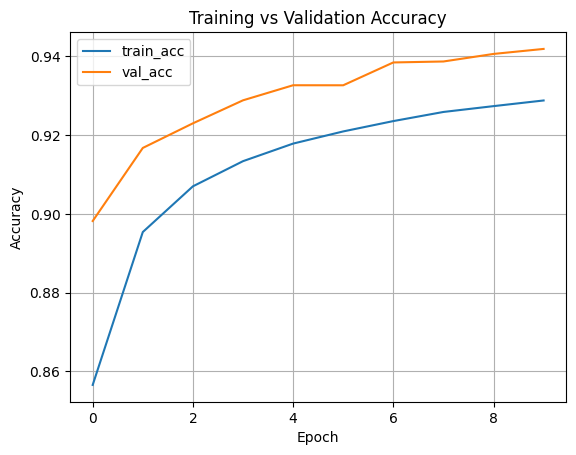

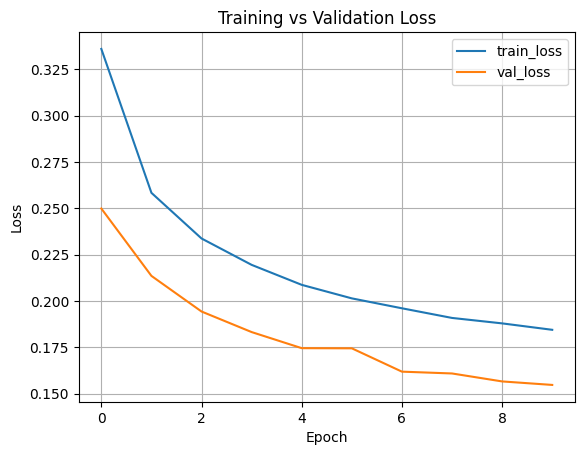

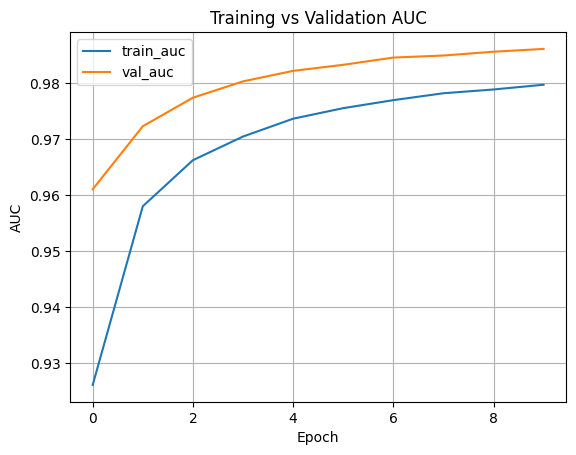

In [27]:

# ================================
# 9) Visualizations (history)
# ================================
# (a) Accuracy
plt.figure()
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Training vs Validation Accuracy'); plt.legend(); plt.grid(True)
plt.show()

# (b) Loss
plt.figure()
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Training vs Validation Loss'); plt.legend(); plt.grid(True)
plt.show()

# (c) AUC
plt.figure()
plt.plot(history.history['auc'], label='train_auc')
plt.plot(history.history['val_auc'], label='val_auc')
plt.xlabel('Epoch'); plt.ylabel('AUC'); plt.title('Training vs Validation AUC'); plt.legend(); plt.grid(True)
plt.show()



Final Validation Results:
Validation Accuracy : 0.9419
Validation Loss     : 0.1547
Validation AUC      : 0.9861


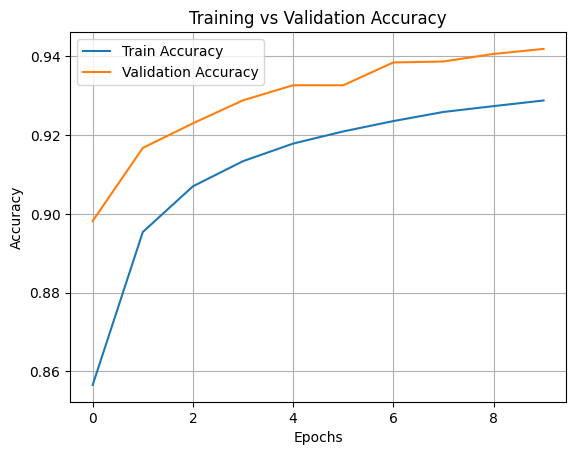

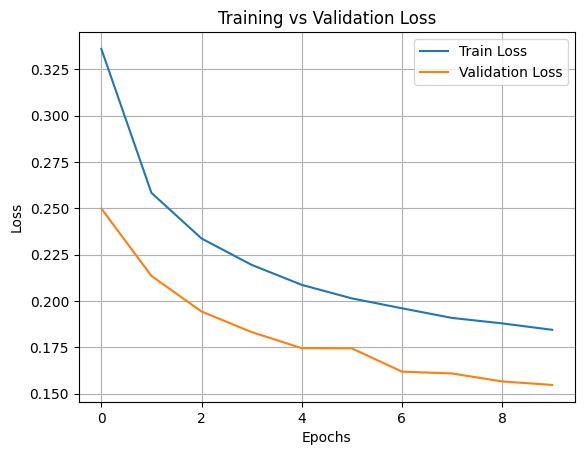

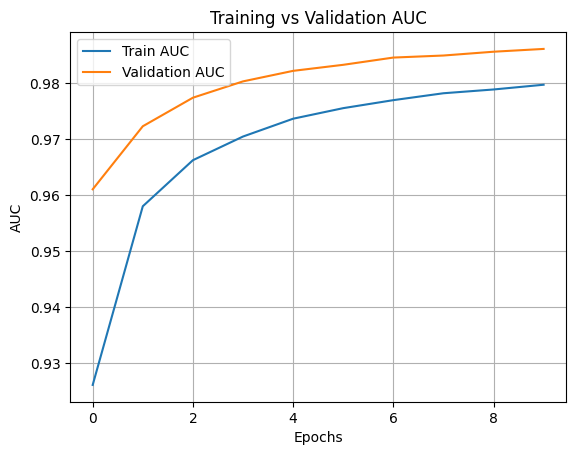

In [28]:
# Show final validation results
final_val_acc  = history.history['val_accuracy'][-1]
final_val_loss = history.history['val_loss'][-1]
final_val_auc  = history.history['val_auc'][-1]

print("Final Validation Results:")
print(f"Validation Accuracy : {final_val_acc:.4f}")
print(f"Validation Loss     : {final_val_loss:.4f}")
print(f"Validation AUC      : {final_val_auc:.4f}")

# Plot training vs validation metrics
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs"); plt.ylabel("Accuracy")
plt.legend(); plt.grid(True)
plt.show()

# Loss
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs"); plt.ylabel("Loss")
plt.legend(); plt.grid(True)
plt.show()

# AUC
plt.figure()
plt.plot(history.history['auc'], label='Train AUC')
plt.plot(history.history['val_auc'], label='Validation AUC')
plt.title("Training vs Validation AUC")
plt.xlabel("Epochs"); plt.ylabel("AUC")
plt.legend(); plt.grid(True)
plt.show()


633/633 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step

Test Accuracy : 0.9423
Test Precision: 0.9442
Test Recall   : 0.9401
Test F1-score : 0.9421
Test ROC-AUC  : 0.9860

Classification report:
               precision    recall  f1-score   support

           0     0.9404    0.9444    0.9424     10122
           1     0.9442    0.9401    0.9421     10125

    accuracy                         0.9423     20247
   macro avg     0.9423    0.9423    0.9423     20247
weighted avg     0.9423    0.9423    0.9423     20247

Confusion matrix:
 [[9559  563]
 [ 606 9519]]


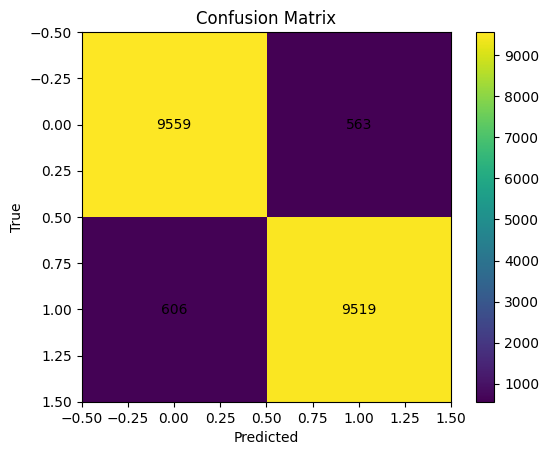

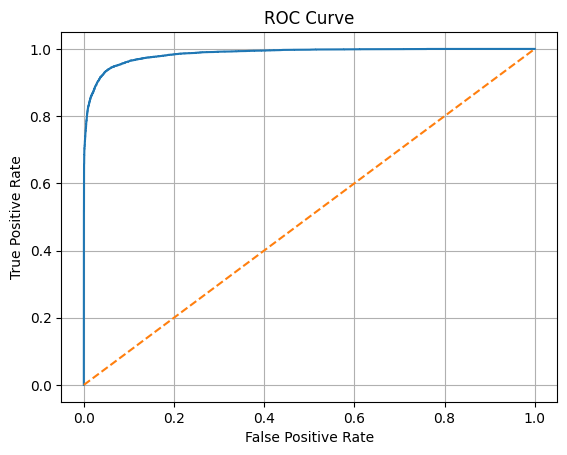

In [29]:
# ================================
# 10) Evaluation on test set
# ================================
y_prob = model.predict(X_test).flatten()
y_pred = (y_prob >= 0.5).astype(int)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec  = recall_score(y_test, y_pred, zero_division=0)
f1   = f1_score(y_test, y_pred, zero_division=0)
auc  = roc_auc_score(y_test, y_prob)

print(f"\nTest Accuracy : {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall   : {rec:.4f}")
print(f"Test F1-score : {f1:.4f}")
print(f"Test ROC-AUC  : {auc:.4f}\n")

print("Classification report:\n", classification_report(y_test, y_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

plt.figure()
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('True')
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha='center', va='center')
plt.colorbar()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC Curve')
plt.grid(True)
plt.show()



